# Exploración de la Tarea 3
Solo exploración: cómo se comporta el pronóstico base, qué sesgo tiene, cómo se ven las features y cómo rinden los **baselines simples** con distintos supuestos de disponibilidad del real (`AVAIL_LAG` = 1..4 días).

Aquí **no hay modelos de aprendizaje**. Su validación cruzada está en `04_validacion_cruzada_t3`.

**Baselines:**
- `base`: el pronóstico original, sin corrección.
- `seasonal_naive`: el real del mismo día de la semana anterior (si no está disponible al emitir, el base).
- `ratio_cd`: factor por CD = suma(real) / suma(pronóstico), con todo lo conocido.
- `ratio_cd_h`: igual, pero un factor por CD y horizonte.
- `ratio_mov14`: factor por CD con solo los últimos 14 días de reales.

**Separación train / test (sin mezclar):**
- **train:** orígenes 22-ene a 13-feb. Aquí se hacen todas las comparaciones; los objetivos evaluados llegan hasta el 14-feb y cada reentrenamiento usa solo lo conocido en su origen.
- **test:** orígenes 14-feb a 28-feb. Cada modelo se entrena **una vez** con lo conocido al inicio de test y se evalúa sin reajustarlo. Objetivos del 15-feb al 1-mar, sin solape con train.

In [1]:
from logforecast import diagnostics, io, plots
from logforecast import evaluation as ev
from logforecast import features as F
from logforecast.config import Settings

S = Settings.from_env()
frame = diagnostics.build_eval_frame(io.load_orders(S), io.load_forecasts(S))
CDS = sorted(frame[F.CD].unique())

## Estabilidad del sesgo del base: primera vs segunda mitad (solo datos de train)
Sesgo = (real - pronóstico) / real total; positivo = el base subestima. Si el signo y la magnitud se mantienen, un factor por CD es defendible.

In [2]:
(diagnostics.bias_stability(frame, ev.ORIG_TEST[0]) * 100).round(1)

bias        wape      
mitad                 1ra   2da   1ra   2da
centro_distribucion                        
CD_CENTRO           -20.2 -20.5  22.9  23.6
CD_ESTE              25.7  24.6  26.3  25.1
CD_NORTE              7.0   8.4  10.0  10.3
CD_OESTE            -24.0 -20.4  25.2  21.8
CD_PACIFICO         -20.6 -21.2  21.1  21.7
CD_SUR               32.0  31.2  32.0  31.2

## Baselines con los 4 rezagos

In [3]:
LAGS = (1, 2, 3, 4)  # días de rezago con que se conoce el real al emitir

MODELOS = {
    "base": ev.SPEC_BASE,
    "seasonal_naive": dict(kind="snaive"),
    "ratio_cd": ev.SPEC_RATIO_CD,
    "ratio_cd_h": dict(kind="ratio", by=[F.CD, F.HOR]),
    "ratio_mov14": dict(kind="ratio_mov", window=14),
}

corridas = ev.run_lags(frame, MODELOS, LAGS)  # L -> (feat, RES, {zona: tabla})
ev.describe_runs(corridas)

,filas train,filas test,filas con que se entrena el modelo de test
AVAIL_LAG,,,
1,516,324,996
2,516,324,972
3,516,324,948
4,516,324,924


## Features (rezago 1): estadísticas y correlaciones
Si `lag7_rel` y `pron_vs_rec7` tienen correlación muy negativa, son casi redundantes; lo mismo con `pico` y `pico_margen`. Esto orienta qué features usar en los modelos del notebook 04.

In [4]:
cols_f = F.CORE + F.EXTRA
feat1 = corridas[1][0]
feat1 = feat1[feat1[F.DESP] <= ev.ORIG_TEST[0]]  # despachos hasta el inicio de test
display(feat1[cols_f + ["y"]].describe().T.round(3))
feat1[cols_f + ["y"]].corr().round(2)

,count,mean,std,min,25%,50%,75%,max
err_7,1020.0,0.033,0.232,-0.260,-0.180,0.000,0.287,0.443
err_14,1020.0,0.031,0.227,-0.256,-0.179,0.000,0.282,0.414
h_dias,1020.0,2.471,1.118,1.000,1.000,2.000,3.000,4.000
dia_semana,1020.0,3.012,1.989,0.000,1.000,3.000,5.000,6.000
finde,1020.0,0.288,0.453,0.000,0.000,0.000,1.000,1.000
pron_vs_rec7,1020.0,-0.035,0.300,-1.456,-0.235,0.000,0.166,0.818
lag7_rel,1020.0,0.024,0.294,-0.864,-0.172,0.000,0.223,1.550
pico,1020.0,0.236,0.425,0.000,0.000,0.000,0.000,1.000
pico_margen,1020.0,-0.090,0.262,-1.589,-0.235,0.000,0.000,0.767
y,1020.0,0.038,0.281,-0.668,-0.194,-0.003,0.263,1.380


,err_7,err_14,h_dias,dia_semana,finde,pron_vs_rec7,lag7_rel,pico,pico_margen,y
err_7,1.00,0.97,-0.00,0.00,0.00,-0.75,0.74,-0.46,-0.61,0.79
err_14,0.97,1.00,-0.00,0.00,0.00,-0.74,0.75,-0.47,-0.63,0.78
h_dias,-0.00,-0.00,1.00,-0.03,-0.02,-0.01,0.02,-0.02,0.01,0.02
dia_semana,0.00,0.00,-0.03,1.00,0.79,-0.19,0.01,-0.07,-0.14,-0.02
finde,0.00,0.00,-0.02,0.79,1.00,-0.19,0.01,-0.06,-0.13,0.00
pron_vs_rec7,-0.75,-0.74,-0.01,-0.19,-0.19,1.00,-0.88,0.58,0.81,-0.82
lag7_rel,0.74,0.75,0.02,0.01,0.01,-0.88,1.00,-0.54,-0.74,0.82
pico,-0.46,-0.47,-0.02,-0.07,-0.06,0.58,-0.54,1.00,0.58,-0.49
pico_margen,-0.61,-0.63,0.01,-0.14,-0.13,0.81,-0.74,0.58,1.00,-0.68
y,0.79,0.78,0.02,-0.02,0.00,-0.82,0.82,-0.49,-0.68,1.00


## Resumen: WAPE global (%) por zona, rezago y baseline
Si el ranking cambia entre filas, el resultado depende del supuesto de disponibilidad del real. Con 1 decimal los ratios parecen idénticos entre rezagos; abajo se ven con 3.

In [5]:
glob, por_cd, dif = ev.summarize_runs(corridas)
display((glob * 100).round(1))
(glob[["base", "ratio_cd", "ratio_cd_h", "ratio_mov14"]] * 100).round(3)

base  seasonal_naive  ratio_cd  ratio_cd_h  ratio_mov14
zona  AVAIL_LAG                                                         
train 1          20.8            12.0       9.5         9.5          9.5
      2          20.8            12.0       9.5         9.5          9.5
      3          20.8            12.0       9.5         9.5          9.5
      4          20.8            14.5       9.5         9.5          9.5
test  1          20.3            13.7       9.1         9.0          9.2
      2          20.3            13.7       9.1         9.0          9.2
      3          20.3            13.7       9.1         9.0          9.1
      4          20.3            15.5       9.1         9.0          9.2

base  ratio_cd  ratio_cd_h  ratio_mov14
zona  AVAIL_LAG                                           
train 1          20.758     9.464       9.494        9.463
      2          20.758     9.463       9.483        9.486
      3          20.758     9.462       9.472        9.521
      4          20.758     9.475       9.474        9.547
test  1          20.315     9.069       8.961        9.171
      2          20.315     9.071       8.976        9.177
      3          20.315     9.071       8.977        9.091
      4          20.315     9.075       8.991        9.165

## WAPE (%) por CD, para cada zona y rezago

In [6]:
(por_cd * 100).round(1)

base  seasonal_naive  ratio_cd  ratio_cd_h  \
zona  AVAIL_LAG CD                                                        
train 1         GLOBAL       20.8            12.0       9.5         9.5   
                CD_CENTRO    22.9            14.4      12.1        12.2   
                CD_ESTE      24.7             8.0      15.1        15.6   
                CD_NORTE     10.2            12.1       7.7         7.6   
                CD_OESTE     22.1            14.9       7.8         7.8   
                CD_PACIFICO  21.7             9.2       8.4         8.4   
                CD_SUR       31.3            11.7       8.8         8.8   
      2         GLOBAL       20.8            12.0       9.5         9.5   
                CD_CENTRO    22.9            14.4      12.1        12.2   
                CD_ESTE      24.7             8.0      15.1        15.5   
                CD_NORTE     10.2            12.1       7.7         7.6   
                CD_OESTE     22.1            14.9       7.8         7.8   
                CD_PACIFICO  21.7             9.2       8.4         8.4   
                CD_SUR       31.3            11.7       8.8         8.8   
      3         GLOBAL       20.8            12.0       9.5         9.5   
                CD_CENTRO    22.9            14.4      12.1        12.1   
                CD_ESTE      24.7             8.0      15.1        15.7   
                CD_NORTE     10.2            12.1       7.7         7.5   
                CD_OESTE     22.1            14.9       7.9         7.8   
                CD_PACIFICO  21.7             9.2       8.4         8.3   
                CD_SUR       31.3            11.7       8.8         8.8   
      4         GLOBAL       20.8            14.5       9.5         9.5   
                CD_CENTRO    22.9            17.0      12.1        12.0   
                CD_ESTE      24.7            12.3      15.2        15.6   
                CD_NORTE     10.2            12.5       7.7         7.5   
                CD_OESTE     22.1            15.5       7.9         7.8   
                CD_PACIFICO  21.7            13.7       8.3         8.4   
                CD_SUR       31.3            16.1       8.9         9.0   
test  1         GLOBAL       20.3            13.7       9.1         9.0   
                CD_CENTRO    21.9            11.5      12.5        12.4   
                CD_ESTE      25.6            13.3      16.1        16.4   
                CD_NORTE      9.1            18.2       7.4         7.1   
                CD_OESTE     23.5            12.0       8.4         8.1   
                CD_PACIFICO  24.5            10.3       8.3         8.6   
                CD_SUR       31.4            10.3       6.8         6.7   
      2         GLOBAL       20.3            13.7       9.1         9.0   
                CD_CENTRO    21.9            11.5      12.5        12.4   
                CD_ESTE      25.6            13.3      16.2        16.6   
                CD_NORTE      9.1            18.2       7.4         7.1   
                CD_OESTE     23.5            12.0       8.4         8.0   
                CD_PACIFICO  24.5            10.3       8.3         8.6   
                CD_SUR       31.4            10.3       6.8         6.7   
      3         GLOBAL       20.3            13.7       9.1         9.0   
                CD_CENTRO    21.9            11.5      12.5        12.5   
                CD_ESTE      25.6            13.3      16.1        16.4   
                CD_NORTE      9.1            18.2       7.4         7.1   
                CD_OESTE     23.5            12.0       8.4         8.0   
                CD_PACIFICO  24.5            10.3       8.3         8.7   
                CD_SUR       31.4            10.3       6.8         6.7   
      4         GLOBAL       20.3            15.5       9.1         9.0   
                CD_CENTRO    21.9            16.0      12.5        12.5   
                CD_ESTE      25.6            15.7     

## Diferencia vs ratio_mov14 (referencia), en puntos de WAPE (negativo = mejora)
Un baseline gana solo si mejora en la mayoría de los CD, no solo en el global.

In [7]:
dif.drop(columns=["base", ev.REF_NAME]).round(2)

seasonal_naive  ratio_cd  ratio_cd_h
zona  AVAIL_LAG CD                                               
train 1         GLOBAL                 2.50      0.00        0.03
                CD_CENTRO              2.30      0.06        0.18
                CD_ESTE               -6.75      0.41        0.87
                CD_NORTE               4.35     -0.08       -0.15
                CD_OESTE               6.79     -0.24       -0.30
                CD_PACIFICO            0.77     -0.07       -0.10
                CD_SUR                 2.95      0.00       -0.00
      2         GLOBAL                 2.47     -0.02       -0.00
                CD_CENTRO              2.30      0.06        0.10
                CD_ESTE               -6.79      0.35        0.75
                CD_NORTE               4.24     -0.19       -0.29
                CD_OESTE               6.82     -0.20       -0.28
                CD_PACIFICO            0.87      0.00        0.01
                CD_SUR                 2.98      0.04        0.11
      3         GLOBAL                 2.44     -0.06       -0.05
                CD_CENTRO              2.22     -0.03       -0.04
                CD_ESTE               -6.75      0.40        0.91
                CD_NORTE               4.23     -0.20       -0.33
                CD_OESTE               6.87     -0.14       -0.17
                CD_PACIFICO            0.88      0.00       -0.01
                CD_SUR                 2.88     -0.05        0.00
      4         GLOBAL                 4.94     -0.07       -0.07
                CD_CENTRO              4.94     -0.03       -0.11
                CD_ESTE               -2.65      0.17        0.65
                CD_NORTE               4.77     -0.12       -0.27
                CD_OESTE               7.51     -0.16       -0.24
                CD_PACIFICO            5.32     -0.01        0.04
                CD_SUR                 7.09     -0.12       -0.03
test  1         GLOBAL                 4.53     -0.10       -0.21
                CD_CENTRO             -1.18     -0.13       -0.22
                CD_ESTE               -2.94     -0.08        0.20
                CD_NORTE              10.63     -0.20       -0.48
                CD_OESTE               2.87     -0.74       -1.10
                CD_PACIFICO            2.22      0.25        0.60
                CD_SUR                 3.62      0.08       -0.02
      2         GLOBAL                 4.52     -0.11       -0.20
                CD_CENTRO             -1.23     -0.18       -0.27
                CD_ESTE               -3.00     -0.11        0.29
                CD_NORTE              10.69     -0.14       -0.41
                CD_OESTE               2.98     -0.63       -1.03
                CD_PACIFICO            2.25      0.28        0.55
                CD_SUR                 3.53      0.01       -0.08
      3         GLOBAL                 4.61     -0.02       -0.11
                CD_CENTRO             -1.07     -0.02       -0.07
                CD_ESTE               -2.79      0.08        0.37
                CD_NORTE              10.74     -0.10       -0.35
                CD_OESTE               3.16     -0.44       -0.83
                CD_PACIFICO            2.25      0.30        0.66
                CD_SUR                 3.58      0.05       -0.06
      4         GLOBAL                 6.29     -0.09       -0.17
                CD_CENTRO              3.45      0.01       -0.02
                CD_ESTE               -0.33      0.12        0.50
                CD_NORTE               8.82     -0.13       -0.40
                CD_OESTE               6.01     -0.63       -1.01
                CD_PACIFICO            5.67      0.23        0.61
                CD_SUR                 7.35     -0.16       -0.25

**CD_ESTE:** es el único CD donde el `seasonal_naive` le gana con claridad a los factores por CD (con rezago 1: 8,0% vs ~15% en train y 13,3% vs ~16% en test). Su sesgo es estable en el tiempo (+25%, ver tabla de estabilidad), pero tiene una dinámica semanal que un factor fijo no captura; por eso es el CD con más error residual tras la corrección.

## Mejor baseline en train, por rezago
Se elige solo con train. Con el rezago por defecto (1) el mejor es `ratio_mov14`, y es la referencia que deben superar los modelos de `04_validacion_cruzada_t3`. Con otros rezagos gana otro ratio, pero las diferencias entre ratios son de centésimas.

In [8]:
glob.loc["train"][list(MODELOS)].idxmin(axis=1).rename("mejor baseline en train")

AVAIL_LAG
1    ratio_mov14
2       ratio_cd
3       ratio_cd
4     ratio_cd_h
Name: mejor baseline en train, dtype: object

## Gráficos por rezago: WAPE por CD en train (izq.) y en test (centro); WAPE global por origen (der.)
La línea punteada marca el inicio de test.

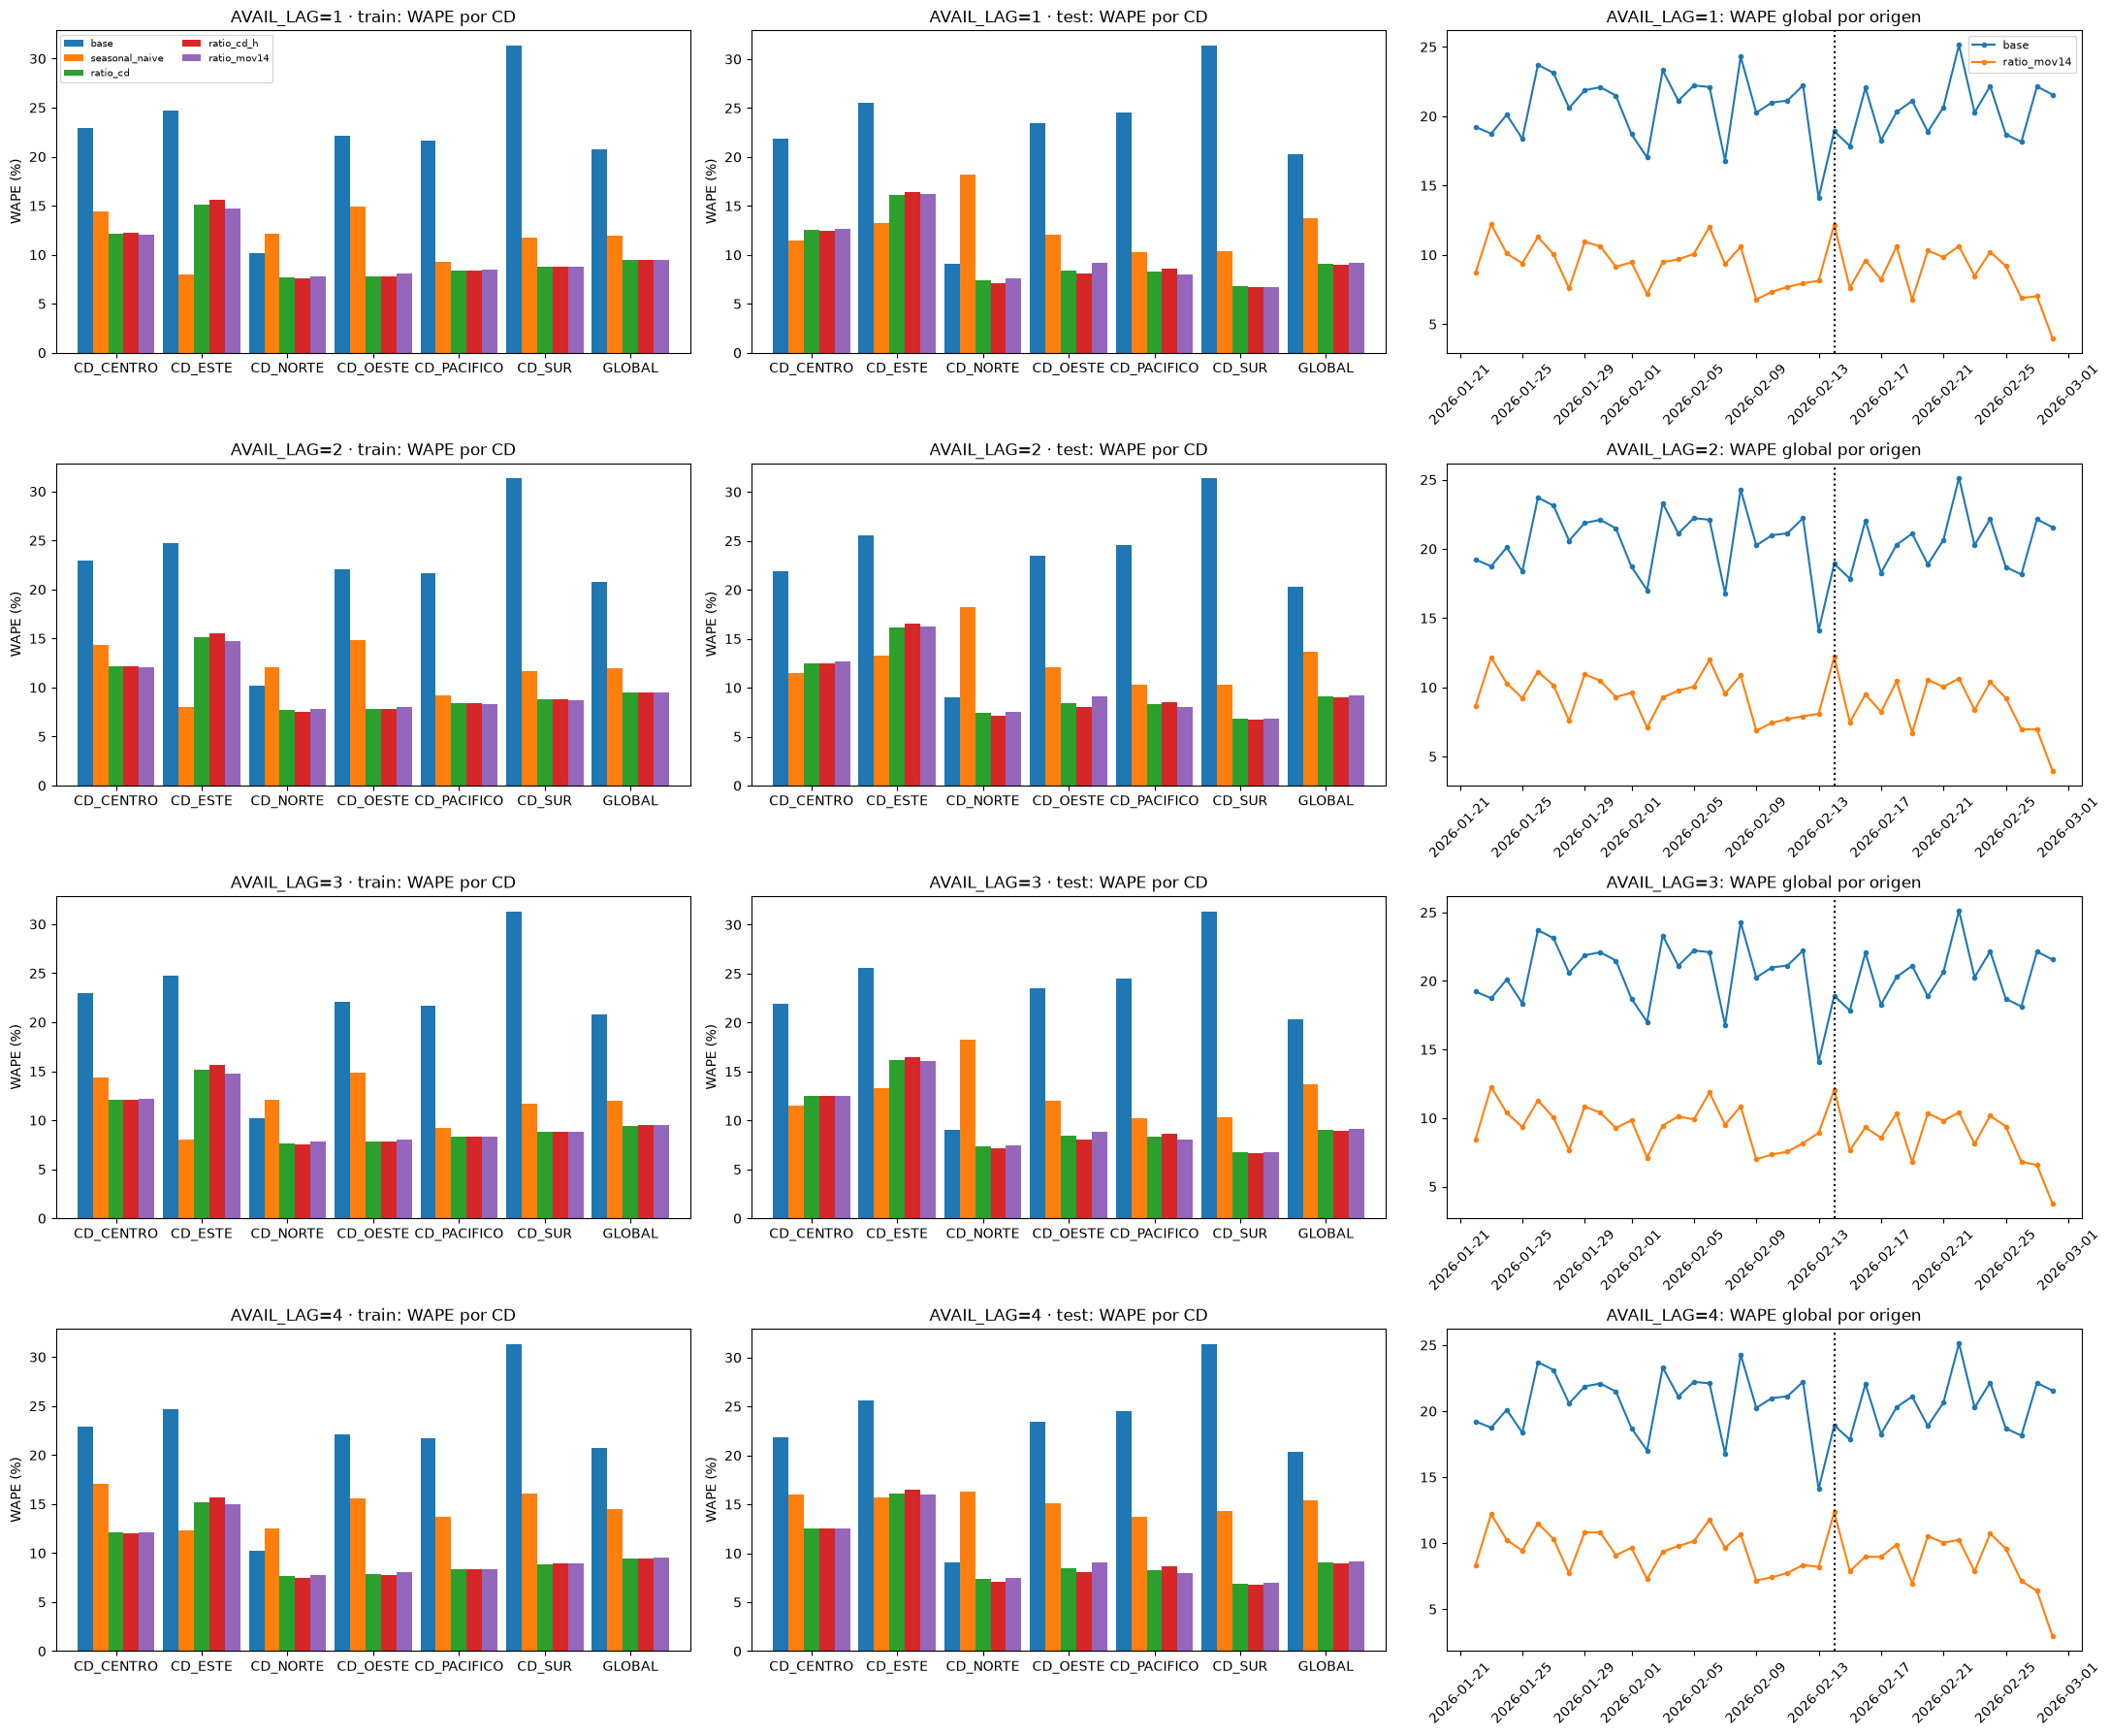

In [9]:
plots.plot_wape_by_lag(corridas, list(MODELOS), ev.ORIG_TEST[0], principales=("base", ev.REF_NAME))

## Real vs base vs ratio_mov14 (D+1), zona test, rezago 1

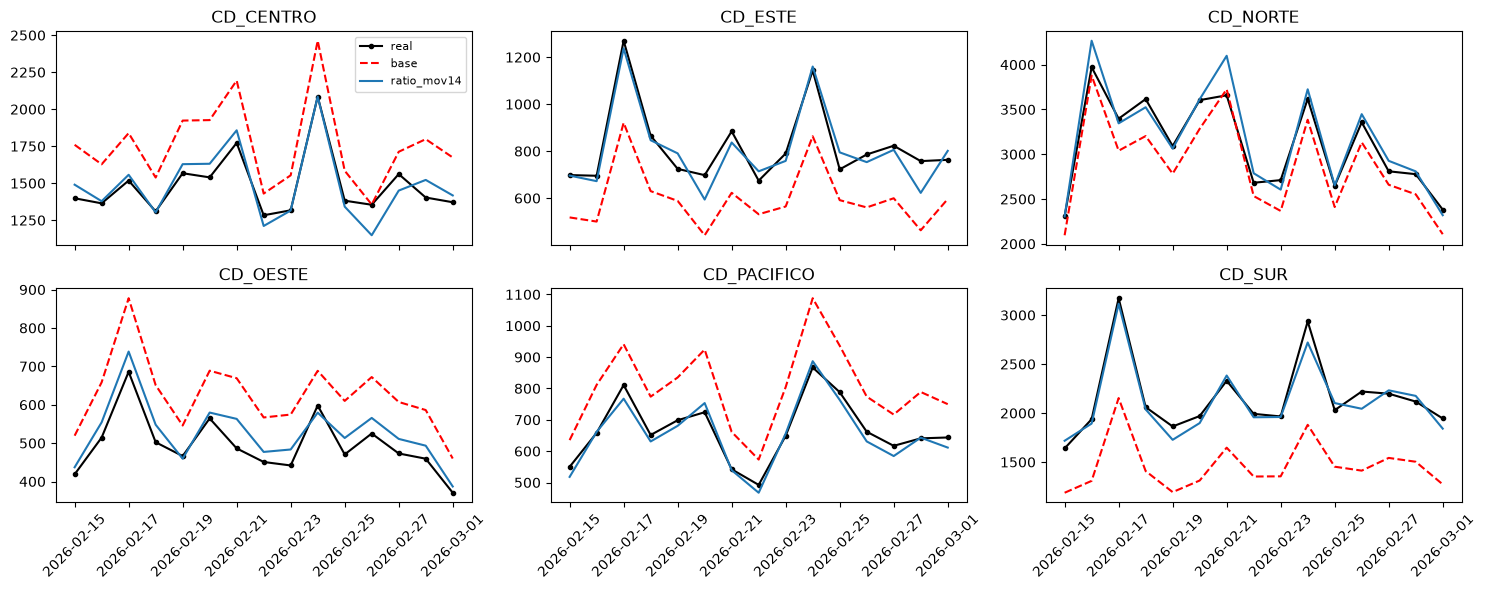

In [10]:
plots.plot_real_vs_pred(corridas[1][1], CDS, curvas=[ev.REF_NAME], h_dias=1, zona="test")

## Limitaciones a declarar
- Los primeros orígenes de train entrenan con pocas filas (el 22-ene hay unos 20 días de historia): train de enero es ruidoso.
- Test son 15 orígenes (~324 filas), unas 2 semanas: diferencias de décimas de punto no son concluyentes.
- En test los parámetros no se actualizan (factor del ratio). Es una prueba más exigente que reentrenar a diario; el sistema real sí reentrenaría.
- Orígenes consecutivos comparten casi todo el entrenamiento, así que no son independientes.
- Con rezago 4 y horizonte D+4, `lag7_rel` no está disponible y vale 0.
- Los modelos de aprendizaje y su validación cruzada están en `04_validacion_cruzada_t3`.